In [296]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [297]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', None)
dt_table= pd.read_csv('https://raw.githubusercontent.com/MaDaiVi/Machine-Learning/refs/heads/Dataset/World_Happines_Report_dataset/2019.csv')
print(dt_table)

     Overall rank         Country or region  Score  GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
0               1                   Finland  7.769           1.340           1.587                    0.986                         0.596       0.153                      0.393
1               2                   Denmark  7.600           1.383           1.573                    0.996                         0.592       0.252                      0.410
2               3                    Norway  7.554           1.488           1.582                    1.028                         0.603       0.271                      0.341
3               4                   Iceland  7.494           1.380           1.624                    1.026                         0.591       0.354                      0.118
4               5               Netherlands  7.488           1.396           1.522                    0.999        

Bước xử lý đầu tiên này chúng em sẽ thực hiện đọc và lấy 6 thuộc tính, tạm thời bỏ qua 3 cột đầu tiên

In [298]:
ten_quoc_gia= dt_table['Country or region']

dt_new= dt_table.iloc[:, 3:].copy()

print(dt_new.head())

print("Kích thước dữ liệu lúc này sẽ là: ", dt_new.shape)

   GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
0           1.340           1.587                    0.986                         0.596       0.153                      0.393
1           1.383           1.573                    0.996                         0.592       0.252                      0.410
2           1.488           1.582                    1.028                         0.603       0.271                      0.341
3           1.380           1.624                    1.026                         0.591       0.354                      0.118
4           1.396           1.522                    0.999                         0.557       0.322                      0.298
Kích thước dữ liệu lúc này sẽ là:  (156, 6)


Ở bước này chúng em sẽ thực hiện chuẩn hóa 6 cột dữ liệu, vì các giá trị này tuy rằng cùng đơn vị do mức đóng góp tính theo điểm trên thang Cantril ladder. Nhưng cùng đơn vị không có nghĩa là cùng độ biến thiên. Vậy nên chuẩn hóa ở bước này là để:
+ Cả sáu yếu tố có trọng số bằng nhau khi tính khoảng cách
+ Giả định mọi yếu tố xã hội quan trọng ngang nhau

In [299]:
from sklearn.preprocessing import StandardScaler

chuan_hoa= StandardScaler()

dt_chuan_hoa= chuan_hoa.fit_transform(dt_new)

print(dt_chuan_hoa[:5])

[[ 1.09504166  1.26809758  1.08042247  1.4242823  -0.33540398  2.99675712]
 [ 1.20332385  1.22115409  1.12185663  1.39627687  0.70726491  3.17715844]
 [ 1.46773387  1.25133205  1.25444597  1.47329179  0.90737308  2.4449413 ]
 [ 1.19576928  1.39216252  1.24615914  1.38927551  1.78152982  0.07850042]
 [ 1.23606033  1.05014566  1.13428688  1.15122941  1.44450554  1.98863208]]


Ở bước này chúng em sẽ tiến hành chọn 2 tham số quan trọng đó là: eps(epsilon) và minPts (MinimumPoint)

với minPts thì em dùng kinh nghiệm thôi đó là tối thiểu thì minPts >= D+1

còn đối với eps thì em thấy là:

Khác với minPts, eps khó chọn bằng một công thức cố định. Một cách phổ biến là sử dụng k-distance graph (biểu đồ khoảng cách láng giềng thứ k).

Ý tưởng:
1. Với mỗi quốc gia, tính khoảng cách đến các quốc gia khác.
2. Lấy khoảng cách đến láng giềng thứ minPts.
3. Sắp xếp các khoảng cách từ nhỏ đến lớn.
4. Vẽ biểu đồ để tìm vị trí đường cong bắt đầu tăng mạnh (điểm khuỷu tay).
5. Chọn eps gần giá trị tại điểm khuỷu tay đó.

Ta sử dụng NearestNeighbors để hỗ trợ tính toán khoảng cách.

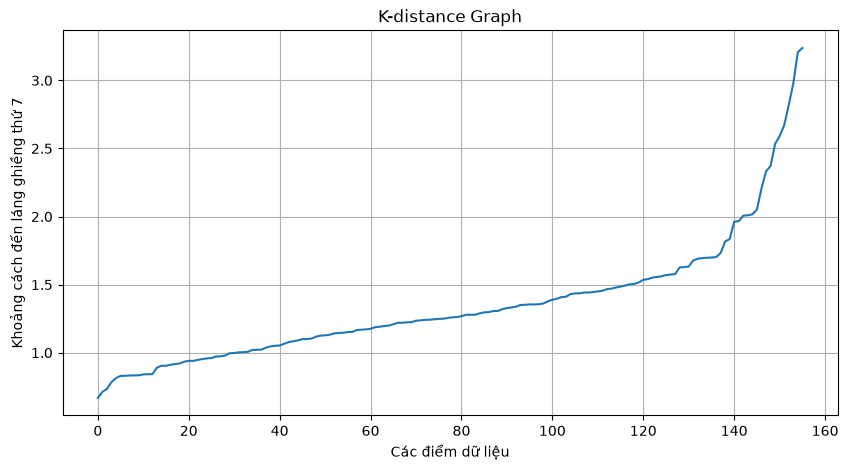

In [300]:
from sklearn.neighbors import NearestNeighbors

min_pts= 7
# eps= 1.8

tim_lang_gieng= NearestNeighbors(n_neighbors=min_pts)
tim_lang_gieng.fit(dt_chuan_hoa)

khoang_cach, chi_so= tim_lang_gieng.kneighbors(dt_chuan_hoa)

khoang_cach_k= khoang_cach[:, min_pts-1]

khoang_cach_k = np.sort(khoang_cach_k)

plt.figure(figsize=(10,5))
plt.plot(khoang_cach_k)
# plt.axhline(y=eps, color='red', linestyle='--', linewidth=1.5, label=f'eps = {eps}')
plt.xlabel('Các điểm dữ liệu')
plt.ylabel(f'Khoảng cách đến láng ghiềng thứ {min_pts}')
plt.title('K-distance Graph')
plt.grid(True)

plt.show()
eps=1.8


Xây dựng các hàm riêng lẻ Thuật toán DBSCAN

In [301]:
import math as m

def euclidean(diem_a, diem_b):
    tong_binh_phuong= 0

    for i in range(len(diem_a)):
        tong_binh_phuong += (diem_a[i] - diem_b[i]) ** 2

    return m.sqrt(tong_binh_phuong)

def tim_neighbor(diem, du_lieu, eps):
    danh_sach_neighbors=[]

    for i in range(len(du_lieu)):
        khoang_cach= euclidean(diem, du_lieu[i])

        if khoang_cach <= eps:
            danh_sach_neighbors.append(i)

    return danh_sach_neighbors

def check_core_point(diem, du_lieu, eps, min_pts):
    danh_sach_neighbors= tim_neighbor(diem, du_lieu, eps)

    if(len(danh_sach_neighbors) >= min_pts):
        return True
    else:
        return False

def mo_rong_clusters(du_lieu, nhan_cum, diem_bat_dau, danh_sach_neighbors, ma_cum, eps, min_pts):
    nhan_cum[diem_bat_dau]= ma_cum

    i=0
    while i < len(danh_sach_neighbors):
        diem_hien_tai= danh_sach_neighbors[i]

        if nhan_cum[diem_hien_tai] == -1:
            nhan_cum[diem_hien_tai] = ma_cum

            neighbors_moi= tim_neighbor(du_lieu[diem_hien_tai], du_lieu, eps)

            if len(neighbors_moi) >= min_pts:
                for diem in neighbors_moi:
                    if diem not in danh_sach_neighbors:
                        danh_sach_neighbors.append(diem)

        i+=1
    return nhan_cum

Thuật toán DBSCAN

In [302]:
def dbscan(du_lieu, eps, min_pts):

    nhan_cum= [-1] * len(du_lieu)
    ma_cum=0

    for i in range(len(du_lieu)):
        if nhan_cum[i] != -1:
            continue

        danh_sach_neighbors= tim_neighbor(du_lieu[i], du_lieu, eps)

        if len(danh_sach_neighbors) <  min_pts:
            continue

        nhan_cum=mo_rong_clusters(du_lieu, nhan_cum, i, danh_sach_neighbors, ma_cum, eps, min_pts)

        ma_cum+=1

    return nhan_cum



In [303]:


nhan_cum= dbscan(dt_chuan_hoa, eps, min_pts)

print("Nhãn các cụm:")
print(nhan_cum)

cac_cum=set(nhan_cum) - {-1}

print("Số cụm tìm được:", len (cac_cum))
print("Số điểm nhiễu:", nhan_cum.count(-1))

for ma_cum in sorted(cac_cum):
    print(f"cụm {ma_cum}: {nhan_cum.count(ma_cum)} quốc gia")



Nhãn các cụm:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, -1, 0]
Số cụm tìm được: 1
Số điểm nhiễu: 7
cụm 0: 149 quốc gia


Giảm dữ liệu từ 6 chiều xuống 2 chiều

In [304]:
from sklearn.decomposition import PCA

giam_chieu= PCA(n_components=2)

du_lieu_2d= giam_chieu.fit_transform(dt_chuan_hoa)

Vẽ biểu đồ, trực quan hóa kết quả

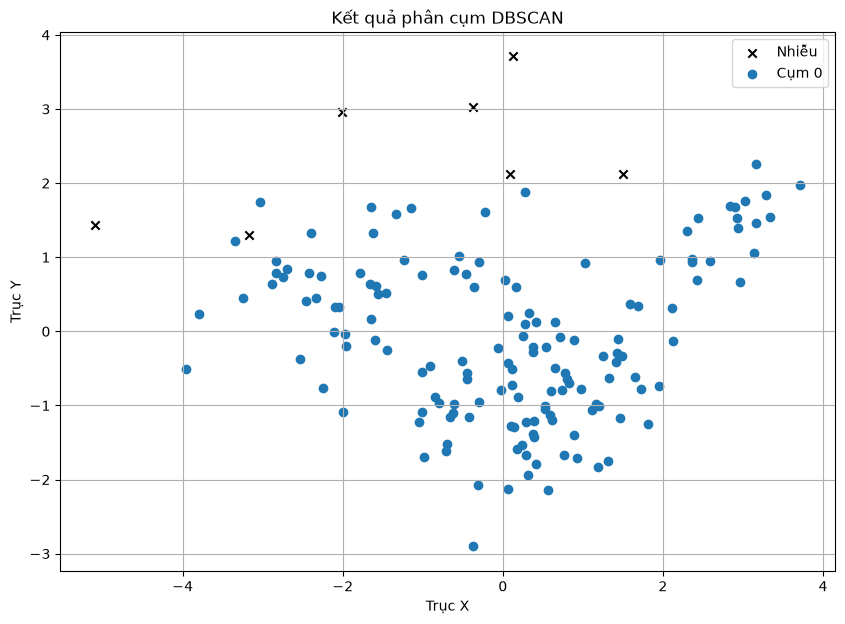

In [305]:
plt.figure(figsize=(10, 7))

for ma_cum in sorted(set(nhan_cum)):

    cac_diem = [
        i for i in range(len(nhan_cum))
        if nhan_cum[i] == ma_cum
    ]

    if ma_cum == -1:
        plt.scatter(
            du_lieu_2d[cac_diem, 0],
            du_lieu_2d[cac_diem, 1],
            color='black',
            marker='x',
            label='Nhiễu'
        )

    else:
        plt.scatter(
            du_lieu_2d[cac_diem, 0],
            du_lieu_2d[cac_diem, 1],
            label=f'Cụm {ma_cum}'
        )

plt.xlabel('Trục X')
plt.ylabel('Trục Y')
plt.title('Kết quả phân cụm DBSCAN')
plt.legend()
plt.grid(True)
plt.show()



In [306]:
print("DANH SÁCH QUỐC GIA THEO CỤM")

for cum in sorted(set(nhan_cum)):
    print(f"\nCụm {cum}:" if cum != -1 else "\nCác quốc gia nhiễu (Noise):")

    for i, nhan in enumerate(nhan_cum):
        if nhan == cum:
            print(f"- {ten_quoc_gia.iloc[i]}")

DANH SÁCH QUỐC GIA THEO CỤM

Các quốc gia nhiễu (Noise):
- Uzbekistan
- Indonesia
- Somalia
- Myanmar
- Syria
- Rwanda
- Central African Republic

Cụm 0:
- Finland
- Denmark
- Norway
- Iceland
- Netherlands
- Switzerland
- Sweden
- New Zealand
- Canada
- Austria
- Australia
- Costa Rica
- Israel
- Luxembourg
- United Kingdom
- Ireland
- Germany
- Belgium
- United States
- Czech Republic
- United Arab Emirates
- Malta
- Mexico
- France
- Taiwan
- Chile
- Guatemala
- Saudi Arabia
- Qatar
- Spain
- Panama
- Brazil
- Uruguay
- Singapore
- El Salvador
- Italy
- Bahrain
- Slovakia
- Trinidad & Tobago
- Poland
- Lithuania
- Colombia
- Slovenia
- Nicaragua
- Kosovo
- Argentina
- Romania
- Cyprus
- Ecuador
- Kuwait
- Thailand
- Latvia
- South Korea
- Estonia
- Jamaica
- Mauritius
- Japan
- Honduras
- Kazakhstan
- Bolivia
- Hungary
- Paraguay
- Northern Cyprus
- Peru
- Portugal
- Pakistan
- Russia
- Philippines
- Serbia
- Moldova
- Libya
- Montenegro
- Tajikistan
- Croatia
- Hong Kong
- Dominica